<a href="https://colab.research.google.com/github/AmiraAbidi2002/vision_OCR/blob/main/Projet_Vision_OCR_LayoutLMv3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# OCR et compréhension de documents : extraction du texte ET de la structure
**Projet Vision par Ordinateur Avancée – 3e année cycle ingénieur**

**Problème** : à partir de l'image scannée d'un formulaire, (1) lire le texte (OCR), puis (2) comprendre sa structure : quels mots sont des *titres*, des *questions (champs)*, des *réponses*, et quelle réponse correspond à quelle question. Sortie finale : un **JSON** structuré.

**Pipeline** : `image → prétraitement → OCR (mots + boîtes) → LayoutLMv3 (étiquetage des mots) → regroupement en entités → liaison question↔réponse → JSON`

| Brique | Outil |
|---|---|
| OCR | Tesseract, EasyOCR (comparés) |
| Compréhension de structure | **LayoutLMv3** (Hugging Face), fine-tuné sur **FUNSD** |
| Contributions | comparaison d'OCR + prétraitement, ablation "avec / sans layout", pipeline bout-en-bout avec vrai OCR, liaison question→réponse, démo Gradio |

**Avant de lancer** : Exécution > Modifier le type d'exécution > **GPU (T4)**. Pour un test rapide, mettre `EPOCHS = 2` (cellule 5).

## 1. Environnement

In [1]:
!apt-get -qq install -y tesseract-ocr > /dev/null
!pip install -q "datasets==3.6.0" transformers seqeval pytesseract easyocr gradio
# Si Colab demande de redémarrer la session : le faire, puis relancer à partir de cette cellule.
import torch, transformers, datasets, sys
print("Python", sys.version.split()[0], "| PyTorch", torch.__version__, "| Transformers", transformers.__version__, "| Datasets", datasets.__version__)
assert torch.cuda.is_available(), "Activez le GPU : Exécution > Modifier le type d'exécution > GPU"
device = torch.device("cuda")
print("GPU :", torch.cuda.get_device_name(0))

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.
Python 3.13.16 | PyTorch 2.14.1+cu130 | Transformers 5.22.1 | Datasets 3.6.0
GPU : Tesla T4


## 2. Dataset FUNSD (formulaires scannés bruités)
199 formulaires annotés : 149 pour l'entraînement, 50 pour le test. Chaque mot a une boîte (coordonnées normalisées 0-1000) et une étiquette : `HEADER`, `QUESTION`, `ANSWER` ou `O` (autre), au format BIO (`B-` début d'entité, `I-` suite).
*Licence : jeu de données destiné à la recherche, vérifier les conditions sur la page du dataset avant toute utilisation commerciale.*

In [2]:
from datasets import load_dataset
try:
    ds = load_dataset("nielsr/funsd-layoutlmv3", trust_remote_code=True)
except Exception as e:
    print("Chargement direct impossible :", repr(e)[:250])
    ds = load_dataset("nielsr/funsd-layoutlmv3", revision="refs/convert/parquet")   # plan B
print(ds)
DEFAULT_LABELS = ["O", "B-HEADER", "I-HEADER", "B-QUESTION", "I-QUESTION", "B-ANSWER", "I-ANSWER"]
try:
    label_names = ds["train"].features["ner_tags"].feature.names
except Exception:
    label_names = DEFAULT_LABELS
id2label = {i: l for i, l in enumerate(label_names)}
label2id = {l: i for i, l in id2label.items()}
print(label_names)

README.md:   0%|          | 0.00/770 [00:00<?, ?B/s]

funsd/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 26.3MB            

funsd/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

funsd/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 9.54MB            

funsd/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/149 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/50 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'bboxes', 'ner_tags', 'image'],
        num_rows: 149
    })
    test: Dataset({
        features: ['id', 'tokens', 'bboxes', 'ner_tags', 'image'],
        num_rows: 50
    })
})
['O', 'B-HEADER', 'I-HEADER', 'B-QUESTION', 'I-QUESTION', 'B-ANSWER', 'I-ANSWER']


## 3. Exploration : images, boîtes et étiquettes

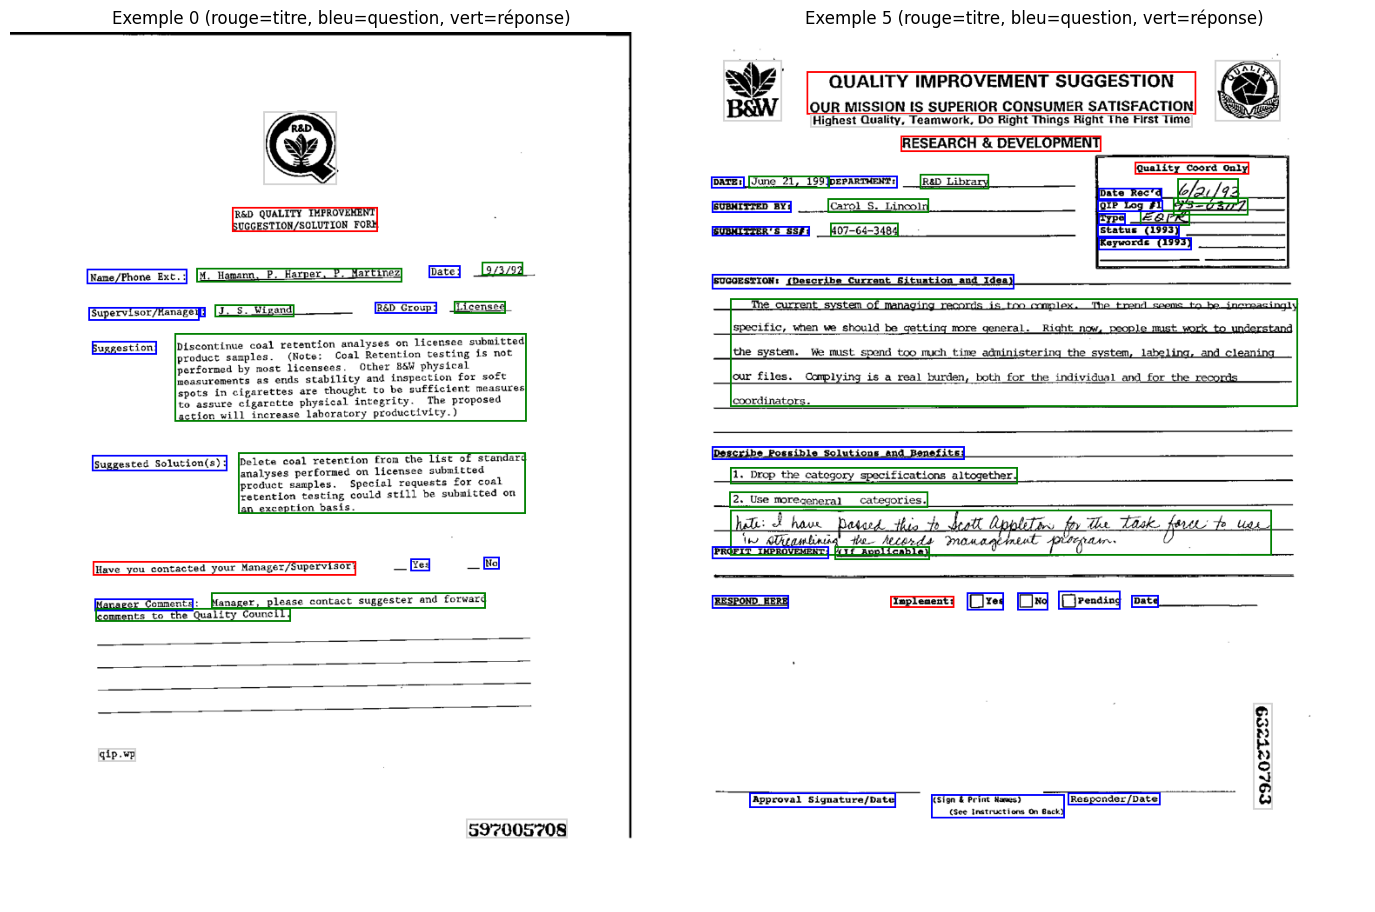

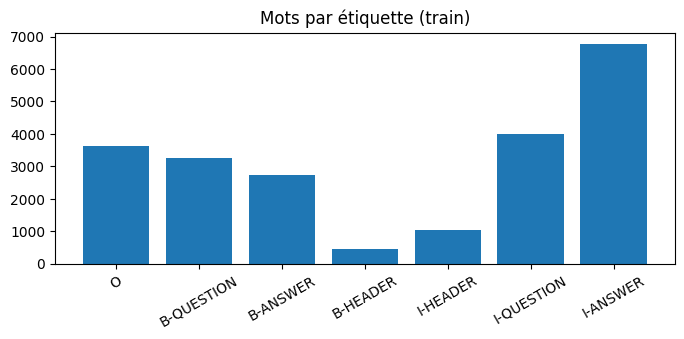

Nombre de mots par document : moyenne = 146 | max = 325


In [3]:
import numpy as np, matplotlib.pyplot as plt, random
from PIL import Image, ImageDraw
from collections import Counter

COLORS = {"HEADER": "red", "QUESTION": "blue", "ANSWER": "green", "O": "lightgray"}

def to_pil(im):
    return im.convert("RGB") if hasattr(im, "convert") else Image.fromarray(np.array(im)).convert("RGB")

def draw_words(pil, boxes, labels):
    img = pil.copy(); d = ImageDraw.Draw(img); W, H = img.size
    for b, l in zip(boxes, labels):
        typ = l.split("-")[-1]
        d.rectangle([b[0]*W/1000, b[1]*H/1000, b[2]*W/1000, b[3]*H/1000], outline=COLORS.get(typ, "black"), width=2)
    return img

fig, ax = plt.subplots(1, 2, figsize=(14, 9))
for a, i in zip(ax, [0, 5]):
    ex = ds["train"][i]
    a.imshow(draw_words(to_pil(ex["image"]), ex["bboxes"], [id2label[t] for t in ex["ner_tags"]])); a.axis("off"); a.set_title(f"Exemple {i} (rouge=titre, bleu=question, vert=réponse)")
plt.tight_layout(); plt.show()

cnt = Counter(id2label[t] for ex in ds["train"] for t in ex["ner_tags"])
plt.figure(figsize=(8, 3)); plt.bar(cnt.keys(), cnt.values()); plt.xticks(rotation=30); plt.title("Mots par étiquette (train)"); plt.show()
print("Nombre de mots par document : moyenne =", int(np.mean([len(e["tokens"]) for e in ds["train"]])), "| max =", max(len(e["tokens"]) for e in ds["train"]))

## 4. Encodage pour LayoutLMv3
Le *processor* transforme chaque document en : `input_ids` (tokens), `bbox` (boîtes 0-1000), `pixel_values` (image 224×224) et `labels`. Les sous-tokens d'un même mot reçoivent `-100` (ignorés par la loss) sauf le premier.
Découpage : train (85 %) / validation (15 %, pour choisir la meilleure epoch) / **test officiel FUNSD (50 docs, jamais vu)**.

In [4]:
from transformers import LayoutLMv3Processor, LayoutLMv3ForTokenClassification, get_linear_schedule_with_warmup
processor = LayoutLMv3Processor.from_pretrained("microsoft/layoutlmv3-base", apply_ocr=False)
MAXLEN = 512

def clip_boxes(boxes):
    return [[max(0, min(1000, int(v))) for v in b] for b in boxes]

def encode_split(raw):
    out = []
    for ex in raw:
        enc = processor(to_pil(ex["image"]), ex["tokens"], boxes=clip_boxes(ex["bboxes"]), word_labels=ex["ner_tags"],
                        truncation=True, padding="max_length", max_length=MAXLEN, return_tensors="pt")
        out.append({k: v.squeeze(0) for k, v in enc.items()})
    return out

tv = ds["train"].train_test_split(test_size=0.15, seed=42)
train_raw, val_raw, test_raw = tv["train"], tv["test"], ds["test"]
print("train / val / test :", len(train_raw), len(val_raw), len(test_raw))
train_enc, val_enc, test_enc = encode_split(train_raw), encode_split(val_raw), encode_split(test_raw)
print({k: tuple(v.shape) for k, v in train_enc[0].items()})

preprocessor_config.json:   0%|          | 0.00/275 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/856 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.14k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

train / val / test : 126 23 50
{'input_ids': (512,), 'attention_mask': (512,), 'bbox': (512, 4), 'labels': (512,), 'pixel_values': (3, 224, 224)}


## 5. Entraînement de LayoutLMv3 (boucle PyTorch écrite à la main)
Modèle de base `microsoft/layoutlmv3-base`, pré-entraîné sur des millions de documents, puis fine-tuné pour classer chaque mot en 7 étiquettes. Loss : entropie croisée par token.
Le paramètre `use_layout=False` sert à l'**ablation** : on met toutes les boîtes à zéro pour mesurer ce que la position apporte.

In [5]:
from torch.utils.data import DataLoader, Dataset
from seqeval.metrics import f1_score, precision_score, recall_score, classification_report
import pandas as pd, time

EPOCHS, LR, BATCH = 15, 5e-5, 4

class EncDS(Dataset):
    def __init__(self, items, use_layout=True): self.items, self.use_layout = items, use_layout
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        it = dict(self.items[i])
        if not self.use_layout: it["bbox"] = torch.zeros_like(it["bbox"])
        return it

@torch.no_grad()
def evaluate(model, items, use_layout=True, report=False):
    model.eval(); preds, golds, losses = [], [], []
    for b in DataLoader(EncDS(items, use_layout), batch_size=8):
        b = {k: v.to(device) for k, v in b.items()}
        with torch.autocast("cuda", dtype=torch.float16):
            out = model(**b)
        losses.append(out.loss.item())
        p, g = out.logits.argmax(-1).cpu().numpy(), b["labels"].cpu().numpy()
        for pi, gi in zip(p, g):
            m = gi != -100
            preds.append([id2label[x] for x in pi[m]]); golds.append([id2label[x] for x in gi[m]])
    res = {"loss": float(np.mean(losses)), "precision": precision_score(golds, preds), "recall": recall_score(golds, preds), "f1": f1_score(golds, preds)}
    if report: res["report"] = classification_report(golds, preds, digits=3)
    return res

def train_model(name, use_layout=True, epochs=EPOCHS, lr=LR, bs=BATCH):
    torch.manual_seed(42)
    model = LayoutLMv3ForTokenClassification.from_pretrained("microsoft/layoutlmv3-base", id2label=id2label, label2id=label2id).to(device)
    loader = DataLoader(EncDS(train_enc, use_layout), batch_size=bs, shuffle=True)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total = epochs * len(loader)
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)
    scaler = torch.amp.GradScaler("cuda")
    hist, best = [], -1
    for ep in range(epochs):
        model.train(); run = 0; t0 = time.time()
        for b in loader:
            b = {k: v.to(device) for k, v in b.items()}
            opt.zero_grad()
            with torch.autocast("cuda", dtype=torch.float16):
                loss = model(**b).loss
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); run += loss.item()
        v = evaluate(model, val_enc, use_layout)
        hist.append({"epoch": ep + 1, "train_loss": run / len(loader), "val_loss": v["loss"], "val_f1": v["f1"]})
        print(f"[{name}] epoch {ep+1:02d}/{epochs} | train_loss {run/len(loader):.4f} | val_loss {v['loss']:.4f} | val_F1 {v['f1']:.3f} | {time.time()-t0:.0f}s")
        if v["f1"] > best:
            best = v["f1"]; model.save_pretrained(f"/content/ckpt_{name}")
    model = LayoutLMv3ForTokenClassification.from_pretrained(f"/content/ckpt_{name}").to(device)   # meilleure epoch
    return model, pd.DataFrame(hist)

model_full, hist_full = train_model("full", use_layout=True)

model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

[transformers] LayoutLMv3ForTokenClassification LOAD REPORT from: microsoft/layoutlmv3-base
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_397/1075659679.py:49: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step(); run += loss.item()


[full] epoch 01/15 | train_loss 1.6515 | val_loss 1.0866 | val_F1 0.590 | 21s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (10 outputs left out)

[full] epoch 08/15 | train_loss 0.0978 | val_loss 1.2172 | val_F1 0.832 | 17s
[full] epoch 09/15 | train_loss 0.0703 | val_loss 1.3875 | val_F1 0.836 | 17s
[full] epoch 10/15 | train_loss 0.0541 | val_loss 1.1168 | val_F1 0.864 | 17s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[full] epoch 11/15 | train_loss 0.0353 | val_loss 1.1771 | val_F1 0.835 | 17s
[full] epoch 12/15 | train_loss 0.0302 | val_loss 1.2946 | val_F1 0.856 | 17s
[full] epoch 13/15 | train_loss 0.0208 | val_loss 1.2614 | val_F1 0.859 | 17s
[full] epoch 14/15 | train_loss 0.0120 | val_loss 1.3111 | val_F1 0.856 | 17s
[full] epoch 15/15 | train_loss 0.0104 | val_loss 1.3353 | val_F1 0.863 | 17s


Loading weights:   0%|          | 0/214 [00:00<?, ?it/s]

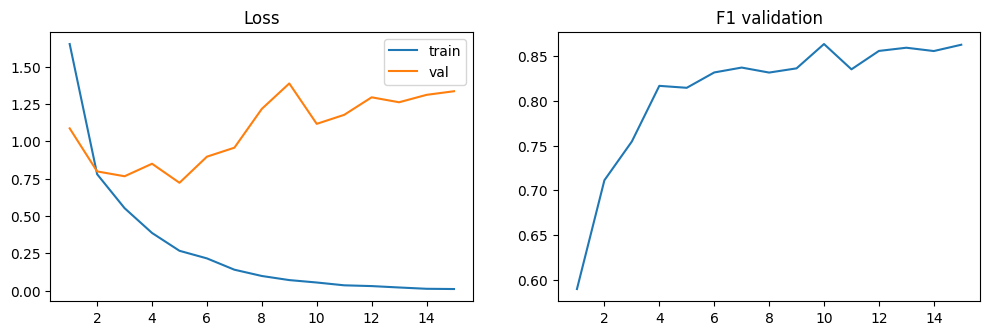

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(hist_full["epoch"], hist_full["train_loss"], label="train"); ax[0].plot(hist_full["epoch"], hist_full["val_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(hist_full["epoch"], hist_full["val_f1"]); ax[1].set_title("F1 validation")
plt.show()   # val_loss qui remonte pendant que train_loss baisse = surapprentissage

## 6. Dimensions des tenseurs (pour le schéma d'architecture)

In [7]:
b = next(iter(DataLoader(EncDS(train_enc), batch_size=2)))
for k, v in b.items(): print(f"{k:15s}", tuple(v.shape), v.dtype)
with torch.no_grad():
    out = model_full(**{k: v.to(device) for k, v in b.items() if k != "labels"}, output_hidden_states=True)
print("\nSortie du dernier bloc Transformer :", tuple(out.hidden_states[-1].shape), "(batch, tokens texte + tokens image, 768)")
print("Logits de classification           :", tuple(out.logits.shape), "(batch, tokens texte, 7 classes)")
print("Nombre de blocs :", len(out.hidden_states) - 1, "| Paramètres :", f"{sum(p.numel() for p in model_full.parameters())/1e6:.0f} M")

input_ids       (2, 512) torch.int64
attention_mask  (2, 512) torch.int64
bbox            (2, 512, 4) torch.int64
labels          (2, 512) torch.int64
pixel_values    (2, 3, 224, 224) torch.float32

Sortie du dernier bloc Transformer : (2, 709, 768) (batch, tokens texte + tokens image, 768)
Logits de classification           : (2, 512, 7) (batch, tokens texte, 7 classes)
Nombre de blocs : 12 | Paramètres : 125 M


## 7. Évaluation sur le TEST (avec les mots annotés : on isole la qualité de la compréhension)

In [8]:
r_full = evaluate(model_full, test_enc, True, report=True)
print(r_full["report"])
print(f"F1 global (entités) = {r_full['f1']:.3f} | précision = {r_full['precision']:.3f} | rappel = {r_full['recall']:.3f}")

              precision    recall  f1-score   support

      ANSWER      0.911     0.917     0.914       805
      HEADER      0.619     0.613     0.616       119
    QUESTION      0.892     0.920     0.906      1049

   micro avg      0.884     0.900     0.892      1973
   macro avg      0.807     0.817     0.812      1973
weighted avg      0.883     0.900     0.892      1973

F1 global (entités) = 0.892 | précision = 0.884 | rappel = 0.900


## 8. Contribution 1 : ablation "le layout sert-il vraiment ?"
Même modèle, mais sans les positions (boîtes à zéro). Si le F1 chute, la structure spatiale est bien ce qui permet de comprendre le document.

In [9]:
RUN_ABLATION = True
if RUN_ABLATION:
    model_nolayout, hist_nl = train_model("nolayout", use_layout=False)
    r_nl = evaluate(model_nolayout, test_enc, False)
    abl = pd.DataFrame({"Modèle": ["LayoutLMv3 complet (texte + layout + image)", "Sans layout (boîtes à zéro)"],
                        "F1": [r_full["f1"], r_nl["f1"]], "Précision": [r_full["precision"], r_nl["precision"]], "Rappel": [r_full["recall"], r_nl["recall"]]}).round(3)
    display(abl)

Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

[transformers] LayoutLMv3ForTokenClassification LOAD REPORT from: microsoft/layoutlmv3-base
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_397/1075659679.py:49: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step(); run += loss.item()


[nolayout] epoch 01/15 | train_loss 1.7057 | val_loss 1.4160 | val_F1 0.351 | 17s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[nolayout] epoch 02/15 | train_loss 1.1880 | val_loss 1.2024 | val_F1 0.475 | 17s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (13 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[nolayout] epoch 13/15 | train_loss 0.0946 | val_loss 1.7299 | val_F1 0.630 | 17s
[nolayout] epoch 14/15 | train_loss 0.0776 | val_loss 1.7058 | val_F1 0.641 | 17s
[nolayout] epoch 15/15 | train_loss 0.0705 | val_loss 1.7126 | val_F1 0.635 | 17s


Loading weights:   0%|          | 0/214 [00:00<?, ?it/s]

,Modèle,F1,Précision,Rappel
0,LayoutLMv3 complet (texte + layout + image),0.892,0.884,0.900
1,Sans layout (boîtes à zéro),0.702,0.682,0.724


## 9. Partie OCR : comparaison de moteurs et prétraitement
Mesure : **F1 sur les mots** (insensible à l'ordre de lecture) entre le texte lu par l'OCR et le texte annoté, sur les 50 documents de test.
Contribution : tester l'effet d'un prétraitement (agrandissement ×2 + binarisation d'Otsu) et du mode de segmentation de Tesseract (`psm`).

In [10]:
import pytesseract, easyocr, cv2, re

def preprocess(pil, scale=2):
    g = cv2.cvtColor(np.array(pil.convert("RGB")), cv2.COLOR_RGB2GRAY)
    g = cv2.resize(g, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
    _, th = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return Image.fromarray(th), scale

def ocr_tesseract(pil, psm=11, prep=False):
    img, s = preprocess(pil) if prep else (pil.convert("RGB"), 1)
    d = pytesseract.image_to_data(img, config=f"--psm {psm}", output_type=pytesseract.Output.DICT)
    res = []
    for t, c, x, y, w, h in zip(d["text"], d["conf"], d["left"], d["top"], d["width"], d["height"]):
        try: c = float(c)
        except Exception: c = -1
        if t.strip() and c >= 10: res.append((t.strip(), [x/s, y/s, (x+w)/s, (y+h)/s]))
    return res

reader = easyocr.Reader(["en"], gpu=True)
def ocr_easyocr(pil):
    res = []
    for poly, text, conf in reader.readtext(np.array(pil.convert("RGB"))):
        xs, ys = [p[0] for p in poly], [p[1] for p in poly]
        x0, x1, y0, y1 = min(xs), max(xs), min(ys), max(ys)
        words = text.split()
        if not words: continue
        total = sum(len(w) for w in words) + len(words) - 1; cur = x0     # EasyOCR rend des lignes : on découpe en mots
        for w in words:
            wl = (x1 - x0) * len(w) / total
            res.append((w, [cur, y0, cur + wl, y1])); cur += wl + (x1 - x0) / total
    return res

def norm_tokens(words):
    return [t for t in (re.sub(r"[^\w]", "", w.lower()) for w in words) if t]

def word_prf(pred_words, gt_words):
    p, g = Counter(norm_tokens(pred_words)), Counter(norm_tokens(gt_words))
    inter = sum((p & g).values())
    pr, rc = inter / max(1, sum(p.values())), inter / max(1, sum(g.values()))
    return pr, rc, 2 * pr * rc / max(1e-9, pr + rc)

OCR_CONFIGS = {
    "Tesseract psm3": lambda im: ocr_tesseract(im, 3, False),
    "Tesseract psm11": lambda im: ocr_tesseract(im, 11, False),
    "Tesseract psm11 + prétraitement": lambda im: ocr_tesseract(im, 11, True),
    "EasyOCR": ocr_easyocr,
}
rows = []
for name, fn in OCR_CONFIGS.items():
    P, R, F = [], [], []; t0 = time.time()
    for ex in test_raw:
        pr, rc, f = word_prf([w for w, _ in fn(to_pil(ex["image"]))], ex["tokens"])
        P.append(pr); R.append(rc); F.append(f)
    rows.append({"Moteur OCR": name, "Précision": np.mean(P), "Rappel": np.mean(R), "F1 mots": np.mean(F), "s / image": (time.time() - t0) / len(test_raw)})
ocr_table = pd.DataFrame(rows).round(3)
display(ocr_table)
BEST_OCR_NAME = ocr_table.sort_values("F1 mots", ascending=False).iloc[0]["Moteur OCR"]
ocr_fn = OCR_CONFIGS[BEST_OCR_NAME]
print("OCR retenu pour le pipeline :", BEST_OCR_NAME)

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

,Moteur OCR,Précision,Rappel,F1 mots,s / image
0,Tesseract psm3,0.718,0.558,0.621,1.738
1,Tesseract psm11,0.714,0.616,0.659,1.801
2,Tesseract psm11 + prétraitement,0.736,0.667,0.696,3.069
3,EasyOCR,0.568,0.481,0.520,1.261


OCR retenu pour le pipeline : Tesseract psm11 + prétraitement


## 10. Pipeline bout-en-bout : image brute → JSON structuré
1. OCR → mots + boîtes · 2. normalisation des boîtes en 0-1000 · 3. LayoutLMv3 étiquette chaque mot · 4. regroupement en entités (B-/I-) · 5. **liaison question → réponse** (heuristique géométrique : réponse à droite ou en dessous, la plus proche).

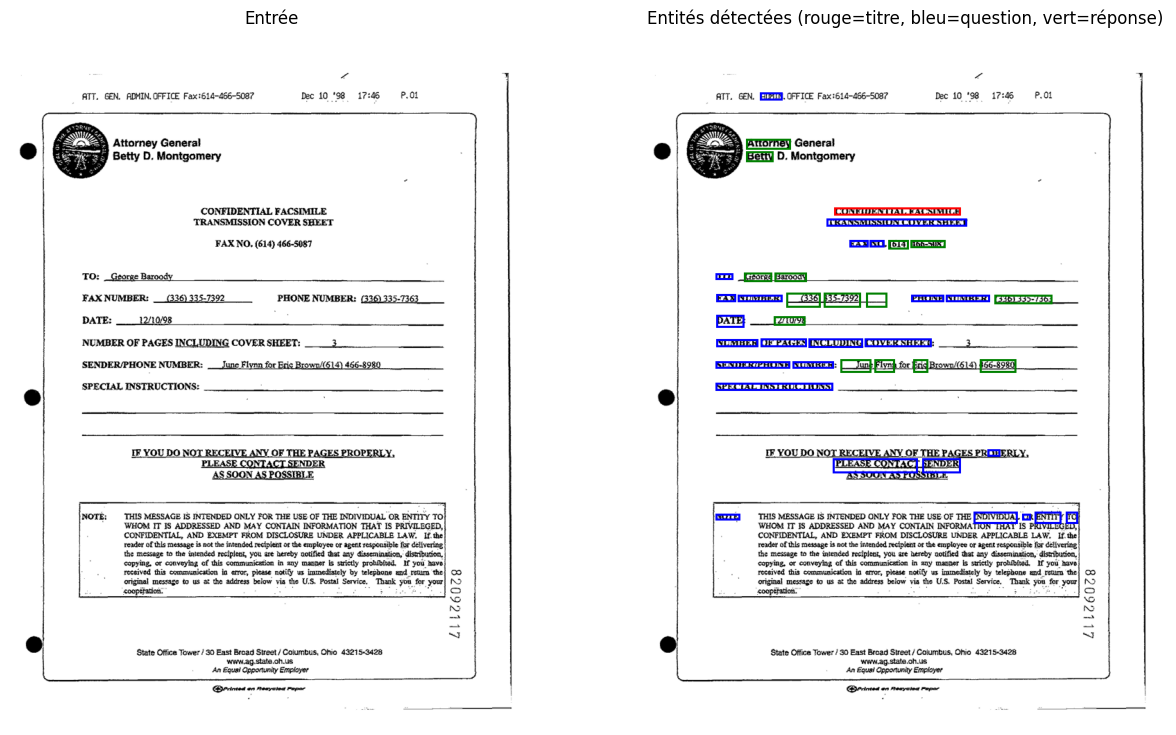

{
  "headers": [
    "CONFIDENTIAL FACSIMILE"
  ],
  "fields": [
    {
      "question": "ADMIN.",
      "answer": "Attorney"
    },
    {
      "question": "TRANSMISSION COVER SHEET",
      "answer": "(614)"
    },
    {
      "question": "FAX",
      "answer": "466-5087"
    },
    {
      "question": "NO.",
      "answer": "__"
    },
    {
      "question": "TO:",
      "answer": "_George"
    },
    {
      "question": "FAX",
      "answer": "__(336)"
    },
    {
      "question": "NUMBER:",
      "answer": "335-7392"
    },
    {
      "question": "PHONE",
      "answer": "(336)335-7363"
    },
    {
      "question": "NUMBER:",
      "answer": "466-8980"
    },
    {
      "question": "DATE:",
      "answer": "12/10/98"
    },
    {
      "question": "OF PAGES",
      "answer": "___June"
    },
    {
      "question": "INCLUDING",
      "answer": "Flynn"
    },
    {
      "question": "COVER SHEET:",
      "answer": "Eric"
    },
    {
      "question": "NUMBER",
      "answer"

In [11]:
def normalize_boxes(boxes, W, H):
    return [[max(0, min(1000, int(1000*b[0]/W))), max(0, min(1000, int(1000*b[1]/H))),
             max(0, min(1000, int(1000*b[2]/W))), max(0, min(1000, int(1000*b[3]/H)))] for b in boxes]

@torch.no_grad()
def predict_words(model, pil, words, boxes):
    model.eval()
    enc = processor(pil, words, boxes=boxes, truncation=True, padding="max_length", max_length=MAXLEN, return_tensors="pt")
    wid = enc.word_ids(0)
    with torch.autocast("cuda", dtype=torch.float16):
        logits = model(**{k: v.to(device) for k, v in enc.items()}).logits[0]
    pred = logits.argmax(-1).cpu().tolist()
    labels, prev = ["O"] * len(words), None
    for i, w in enumerate(wid):
        if w is not None and w != prev: labels[w] = id2label[pred[i]]
        prev = w
    return labels

def group_entities(words, labels, boxes):
    ents, cur = [], None
    for w, l, b in zip(words, labels, boxes):
        if l == "O": cur = None; continue
        tag, typ = l.split("-", 1)
        if cur is None or tag == "B" or typ != cur["label"]:
            cur = {"label": typ, "words": [w], "box": list(b)}; ents.append(cur)
        else:
            cur["words"].append(w)
            cur["box"] = [min(cur["box"][0], b[0]), min(cur["box"][1], b[1]), max(cur["box"][2], b[2]), max(cur["box"][3], b[3])]
    for e in ents: e["text"] = " ".join(e["words"])
    return ents

def link_kv(ents, max_dist=400):
    qs = sorted([e for e in ents if e["label"] == "QUESTION"], key=lambda e: (e["box"][1], e["box"][0]))
    ans, used, pairs = [e for e in ents if e["label"] == "ANSWER"], set(), []
    for q in qs:
        qx0, qy0, qx1, qy1 = q["box"]; qcy = (qy0 + qy1) / 2; best, bscore = None, 1e9
        for j, a in enumerate(ans):
            if j in used: continue
            ax0, ay0, ax1, ay1 = a["box"]; acy = (ay0 + ay1) / 2
            if ax0 >= qx1 - 20:        score = abs(ax0 - qx1) + 3 * abs(acy - qcy)      # réponse à droite
            elif ay0 >= qy1 - 10:      score = abs(ax0 - qx0) + 3 * abs(ay0 - qy1)      # réponse en dessous
            else: continue
            if score < bscore: best, bscore = j, score
        if best is not None and bscore < max_dist:
            used.add(best); pairs.append({"question": q["text"], "answer": ans[best]["text"]})
        else:
            pairs.append({"question": q["text"], "answer": None})
    return pairs

def run_pipeline(pil, model=None, ocr=None):
    model, ocr = model or model_full, ocr or ocr_fn
    pil = pil.convert("RGB"); W, H = pil.size
    res = ocr(pil)
    if not res: return {"words": [], "entities": [], "json": {"headers": [], "fields": []}}
    words = [w for w, _ in res]; boxes = normalize_boxes([b for _, b in res], W, H)
    labels = predict_words(model, pil, words, boxes)
    ents = group_entities(words, labels, boxes)
    return {"words": words, "boxes": boxes, "labels": labels, "entities": ents,
            "json": {"headers": [e["text"] for e in ents if e["label"] == "HEADER"], "fields": link_kv(ents)}}

def draw_entities(pil, ents):
    img = pil.convert("RGB").copy(); d = ImageDraw.Draw(img); W, H = img.size
    for e in ents:
        b = e["box"]; c = COLORS.get(e["label"], "black")
        d.rectangle([b[0]*W/1000, b[1]*H/1000, b[2]*W/1000, b[3]*H/1000], outline=c, width=3)
    return img

import json
ex = test_raw[0]; pil = to_pil(ex["image"]); out = run_pipeline(pil)
fig, ax = plt.subplots(1, 2, figsize=(15, 9))
ax[0].imshow(pil); ax[0].set_title("Entrée"); ax[1].imshow(draw_entities(pil, out["entities"])); ax[1].set_title("Entités détectées (rouge=titre, bleu=question, vert=réponse)")
for a in ax: a.axis("off")
plt.show()
print(json.dumps(out["json"], indent=2, ensure_ascii=False)[:1500])

## 11. Évaluation bout-en-bout au niveau des entités
Une entité prédite est correcte si son étiquette est la même **et** si son texte ressemble à ≥ 80 % (`difflib`) à une entité annotée.
On compare deux cas : (a) mots annotés parfaits (la compréhension seule) et (b) OCR réel. **L'écart mesure l'effet des erreurs d'OCR qui se propagent.**

In [12]:
from difflib import SequenceMatcher

def entity_prf(gt, pr, thr=0.8):
    used, tp = set(), 0
    for g in gt:
        for j, p in enumerate(pr):
            if j in used or p["label"] != g["label"]: continue
            if SequenceMatcher(None, g["text"].lower(), p["text"].lower()).ratio() >= thr: used.add(j); tp += 1; break
    P, R = tp / max(1, len(pr)), tp / max(1, len(gt))
    return P, R, 2 * P * R / max(1e-9, P + R)

res_gt, res_ocr, per_doc = [], [], []
for i, ex in enumerate(test_raw):
    pil = to_pil(ex["image"]); gt_l = [id2label[t] for t in ex["ner_tags"]]
    gt_e = group_entities(ex["tokens"], gt_l, ex["bboxes"])
    # (a) mots annotés
    pl = predict_words(model_full, pil, ex["tokens"], clip_boxes(ex["bboxes"]))
    res_gt.append(entity_prf(gt_e, group_entities(ex["tokens"], pl, ex["bboxes"])))
    # (b) OCR réel
    o = run_pipeline(pil); r = entity_prf(gt_e, o["entities"]); res_ocr.append(r); per_doc.append((i, r[2]))

e2e = pd.DataFrame({"Entrée du modèle": ["Mots annotés (OCR parfait)", f"OCR réel ({BEST_OCR_NAME})"],
                    "Précision": [np.mean([r[0] for r in res_gt]), np.mean([r[0] for r in res_ocr])],
                    "Rappel":    [np.mean([r[1] for r in res_gt]), np.mean([r[1] for r in res_ocr])],
                    "F1 entités":[np.mean([r[2] for r in res_gt]), np.mean([r[2] for r in res_ocr])]}).round(3)
display(e2e)

,Entrée du modèle,Précision,Rappel,F1 entités
0,Mots annotés (OCR parfait),0.891,0.892,0.889
1,OCR réel (Tesseract psm11 + prétraitement),0.217,0.370,0.268


## 12. Cas de réussite et d'échec (pour la présentation)

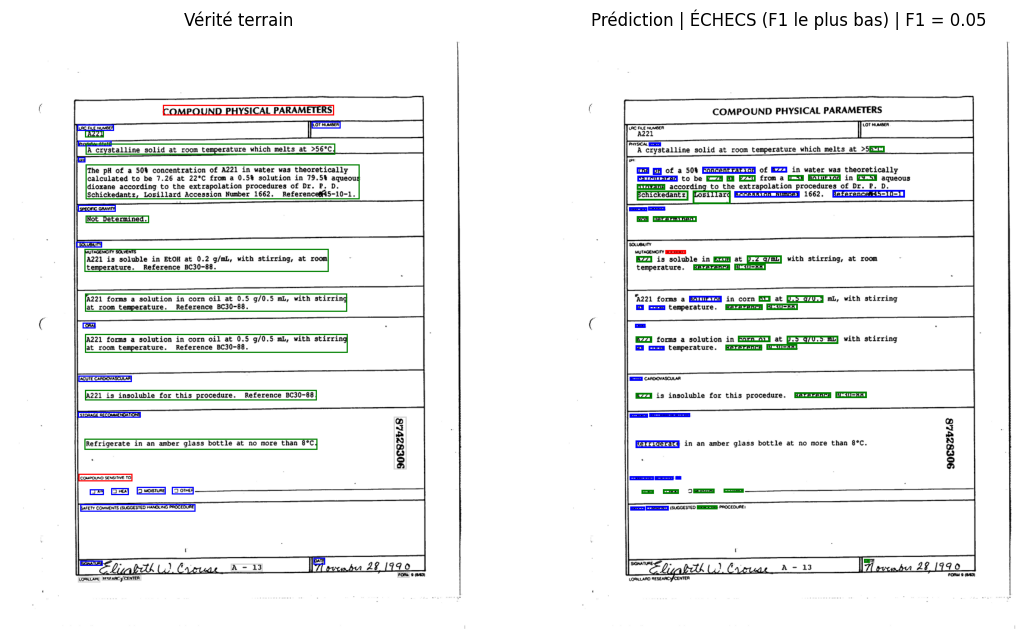

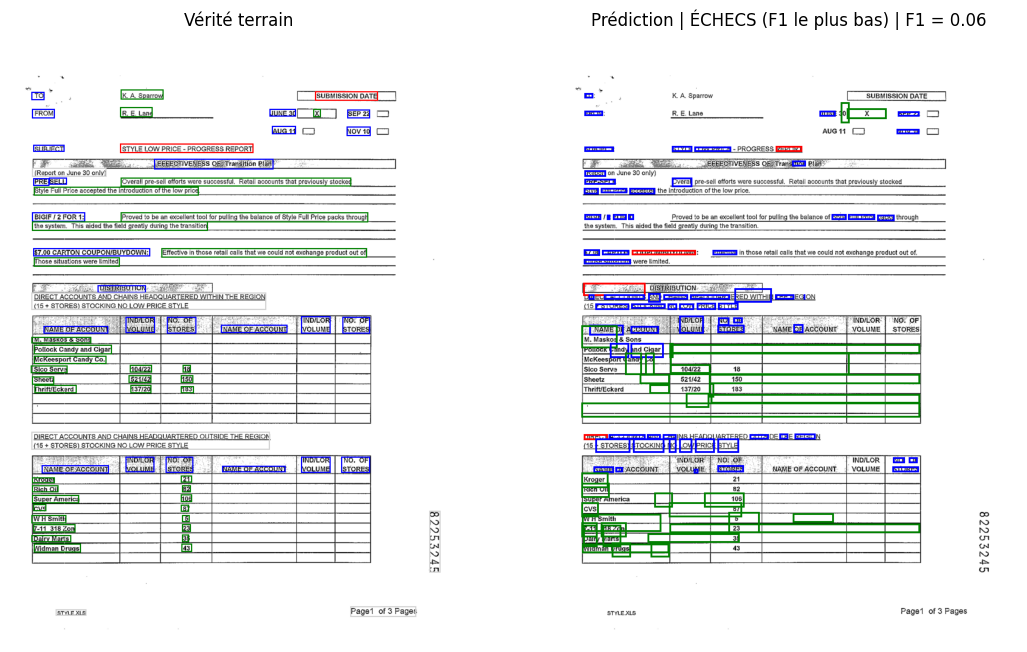

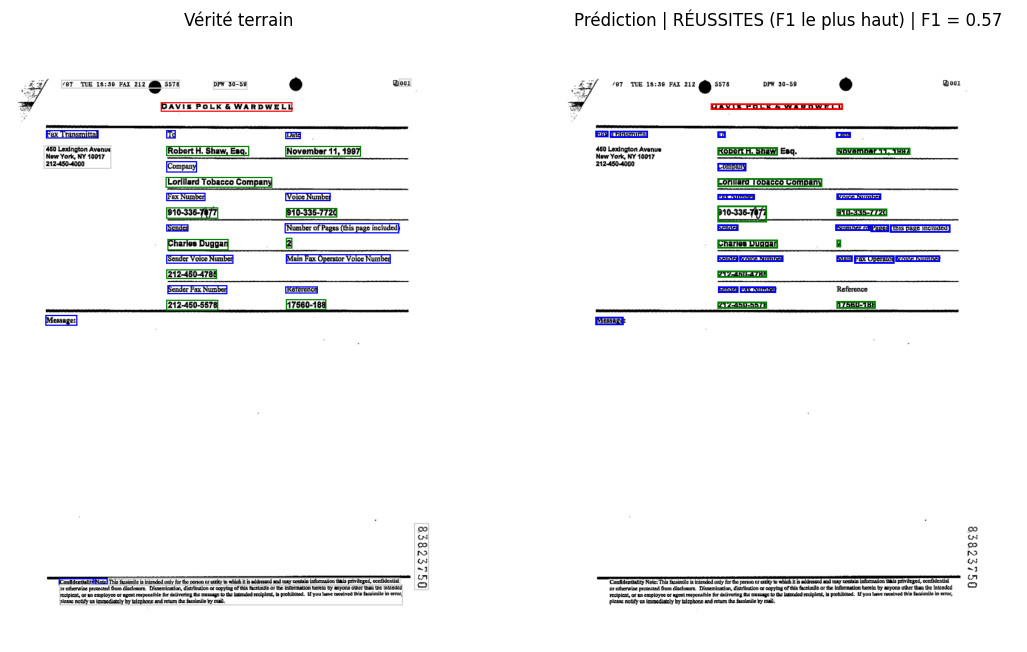

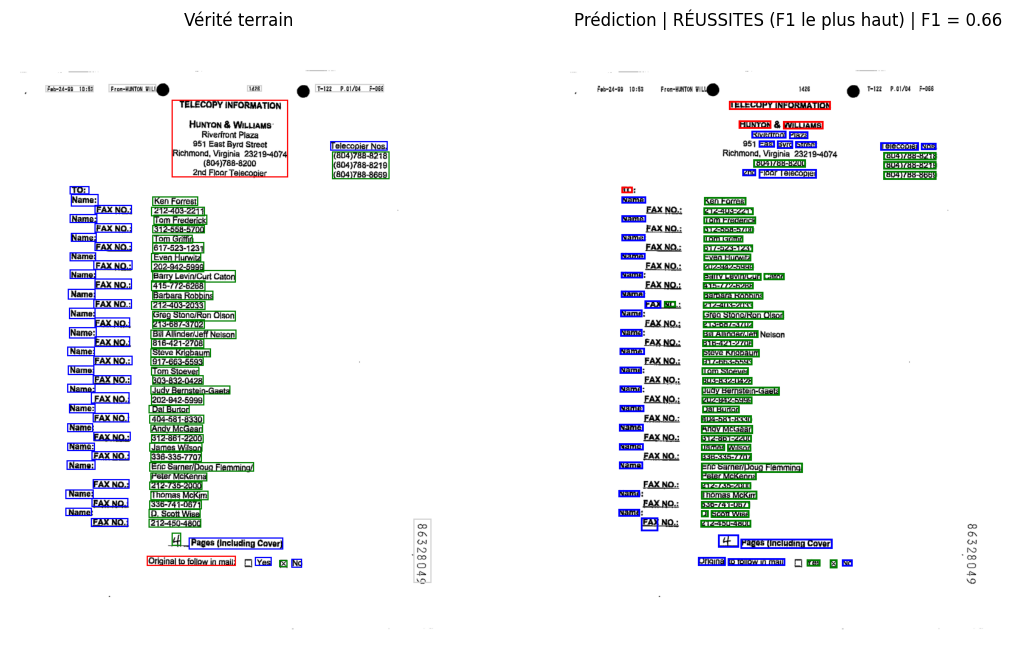

In [13]:
per_doc.sort(key=lambda x: x[1])
for title, idxs in [("ÉCHECS (F1 le plus bas)", per_doc[:2]), ("RÉUSSITES (F1 le plus haut)", per_doc[-2:])]:
    for i, f in idxs:
        pil = to_pil(test_raw[i]["image"]); o = run_pipeline(pil)
        fig, ax = plt.subplots(1, 2, figsize=(13, 8))
        ax[0].imshow(draw_words(pil, test_raw[i]["bboxes"], [id2label[t] for t in test_raw[i]["ner_tags"]])); ax[0].set_title("Vérité terrain")
        ax[1].imshow(draw_entities(pil, o["entities"])); ax[1].set_title(f"Prédiction | {title} | F1 = {f:.2f}")
        for a in ax: a.axis("off")
        plt.show()

## 13. Démo interactive (Gradio) : à lancer en direct
Charger une image de formulaire. **Attention** : le modèle est entraîné sur des formulaires anglais type FUNSD. Sur un autre type de document (facture, reçu), la qualité baissera, ce qui est une limite à présenter honnêtement.

In [14]:
import gradio as gr

def demo_fn(image):
    pil = Image.fromarray(image).convert("RGB")
    out = run_pipeline(pil)
    return draw_entities(pil, out["entities"]), out["json"]

examples_dir = "/content/examples"; import os; os.makedirs(examples_dir, exist_ok=True)
ex_paths = []
for i in range(3):
    p = f"{examples_dir}/test_{i}.png"; to_pil(test_raw[i]["image"]).save(p); ex_paths.append([p])

demo = gr.Interface(fn=demo_fn, inputs=gr.Image(type="numpy", label="Document scanné"),
                    outputs=[gr.Image(label="Structure détectée"), gr.JSON(label="Extraction structurée")],
                    examples=ex_paths, title="OCR + compréhension de documents (Tesseract/EasyOCR + LayoutLMv3)")
demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://06f27b121cf973acdf.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 14. Sauvegarde, publication et reproductibilité

In [15]:
model_full.save_pretrained("/content/layoutlmv3-funsd-final"); processor.save_pretrained("/content/layoutlmv3-funsd-final")
results = {"test_f1_with_gt_words": r_full["f1"], "ocr_table": ocr_table.to_dict("records"), "end_to_end": e2e.to_dict("records")}
if RUN_ABLATION: results["ablation"] = abl.to_dict("records")
json.dump(results, open("/content/results.json", "w"), indent=2, default=float)
!pip freeze | grep -iE "^(torch|transformers|datasets|seqeval|pytesseract|easyocr|opencv|gradio|numpy|pillow|pandas)" > /content/requirements_versions.txt
!cat /content/requirements_versions.txt
!tesseract --version | head -1
# Publier sur Hugging Face (exigé : lien du projet) :
# from huggingface_hub import notebook_login; notebook_login()
# model_full.push_to_hub("VOTRE_PSEUDO/layoutlmv3-funsd"); processor.push_to_hub("VOTRE_PSEUDO/layoutlmv3-funsd")
# from google.colab import files; files.download("/content/results.json")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

datasets==3.6.0
easyocr==1.7.2
gradio==6.31.0
gradio_client==2.7.2
numpy==2.4.6
opencv-contrib-python==4.14.0.94
opencv-python==5.0.0.93
opencv-python-headless==5.0.0.93
pandas==2.2.3
pandas-datareader==0.11.1
pandas-gbq==0.30.0
pandas-stubs==2.2.3.250527
pillow==11.3.0
pytesseract==0.3.13
seqeval==1.2.2
torch==2.14.1+cu130
torchao==0.10.0
torchaudio==2.11.0+cu130
torchcodec==0.17.0+cu130
torchdata==0.11.0
torchsummary==1.5.1
torchtune==0.6.1
torchvision==0.29.1+cu130
transformers==5.22.1
tesseract 5.3.4


## 15. Journal des difficultés (2 minimum exigées : capture + causes + solution + preuve)
| # | Problème | Message d'erreur / capture | Causes | Solution retenue | Preuve après correction |
|---|---|---|---|---|---|
| 1 | | | | | |
| 2 | | | | | |

*Difficultés réalistes sur ce projet* :
- `Dataset scripts are no longer supported` → version de `datasets` trop récente (d'où le `datasets==3.6.0`).
- `bbox must be between 0 and 1000` → boîtes non normalisées ou hors image (d'où `clip_boxes`).
- `CUDA out of memory` → réduire `BATCH` (4 → 2) ou `MAXLEN`.
- Étiquettes mal alignées avec les sous-tokens (`-100`, première sous-partie du mot seulement).
- Documents de plus de 512 tokens tronqués (la fin du formulaire n'est pas analysée).
- Surapprentissage : `val_loss` qui remonte (149 documents seulement).
- Lignes lues par EasyOCR qu'il faut découper en mots ; ordre de lecture de Tesseract différent de l'ordre annoté.
- Erreurs d'OCR qui se propagent au modèle de structure (voir tableau section 11).